# Dataset Creation - Part A
מחברת זו מבצעת: חישת נתונים, בדיקות איכות, הכנה ויצירת משתנה המטרה RainTomorrow.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

sns.set_theme(style="whitegrid")
RAW_PATH = Path("data/raw/sensed_data.csv")
PROCESSED_PATH = Path("data/processed/final_dataset.csv")

In [2]:
df = pd.read_csv(RAW_PATH)
df.head()

,location,date,weather_code,temperature_2m_max,temperature_2m_min,temperature_2m_mean,apparent_temperature_mean,precipitation_sum,rain_sum,precipitation_hours,wind_speed_10m_max,wind_direction_10m_dominant,relative_humidity_2m_mean,dew_point_2m_mean,pressure_msl_mean,cloud_cover_mean,wind_gusts_10m_max,sunshine_duration,shortwave_radiation_sum,et0_fao_evapotranspiration
0,berlin,2010-01-01,73,-1.6,-3.2,-2.5,-7.2,3.2,0.0,12.0,16.3,44,86,-4.6,998.2,99,31.3,0.00,1.82,0.30
1,berlin,2010-01-02,71,-1.2,-5.7,-3.2,-7.6,1.1,0.0,9.0,15.8,324,90,-4.6,1011.5,97,23.0,2114.82,2.55,0.23
2,berlin,2010-01-03,71,-4.9,-8.9,-6.7,-10.5,0.0,0.0,0.0,7.3,49,93,-7.6,1020.2,94,19.4,12470.87,2.50,0.14
3,berlin,2010-01-04,3,-6.3,-9.6,-7.6,-12.0,0.0,0.0,0.0,13.0,215,90,-9.0,1017.6,92,23.8,0.00,2.02,0.16
4,berlin,2010-01-05,3,-5.4,-11.7,-7.7,-12.3,0.0,0.0,0.0,11.2,176,88,-9.4,1010.3,90,21.6,18052.82,2.74,0.21


## Data Quality Checks

In [3]:
quality = pd.DataFrame({
    "missing_count": df.isna().sum(),
    "missing_ratio": df.isna().mean().round(4),
    "dtype": df.dtypes.astype(str)
}).sort_values("missing_ratio", ascending=False)
quality.head(20)

,missing_count,missing_ratio,dtype
location,0,0.0,object
date,0,0.0,object
weather_code,0,0.0,int64
temperature_2m_max,0,0.0,float64
temperature_2m_min,0,0.0,float64
temperature_2m_mean,0,0.0,float64
apparent_temperature_mean,0,0.0,float64
precipitation_sum,0,0.0,float64
rain_sum,0,0.0,float64
precipitation_hours,0,0.0,float64


## Distributions (at least 7 numeric variables)

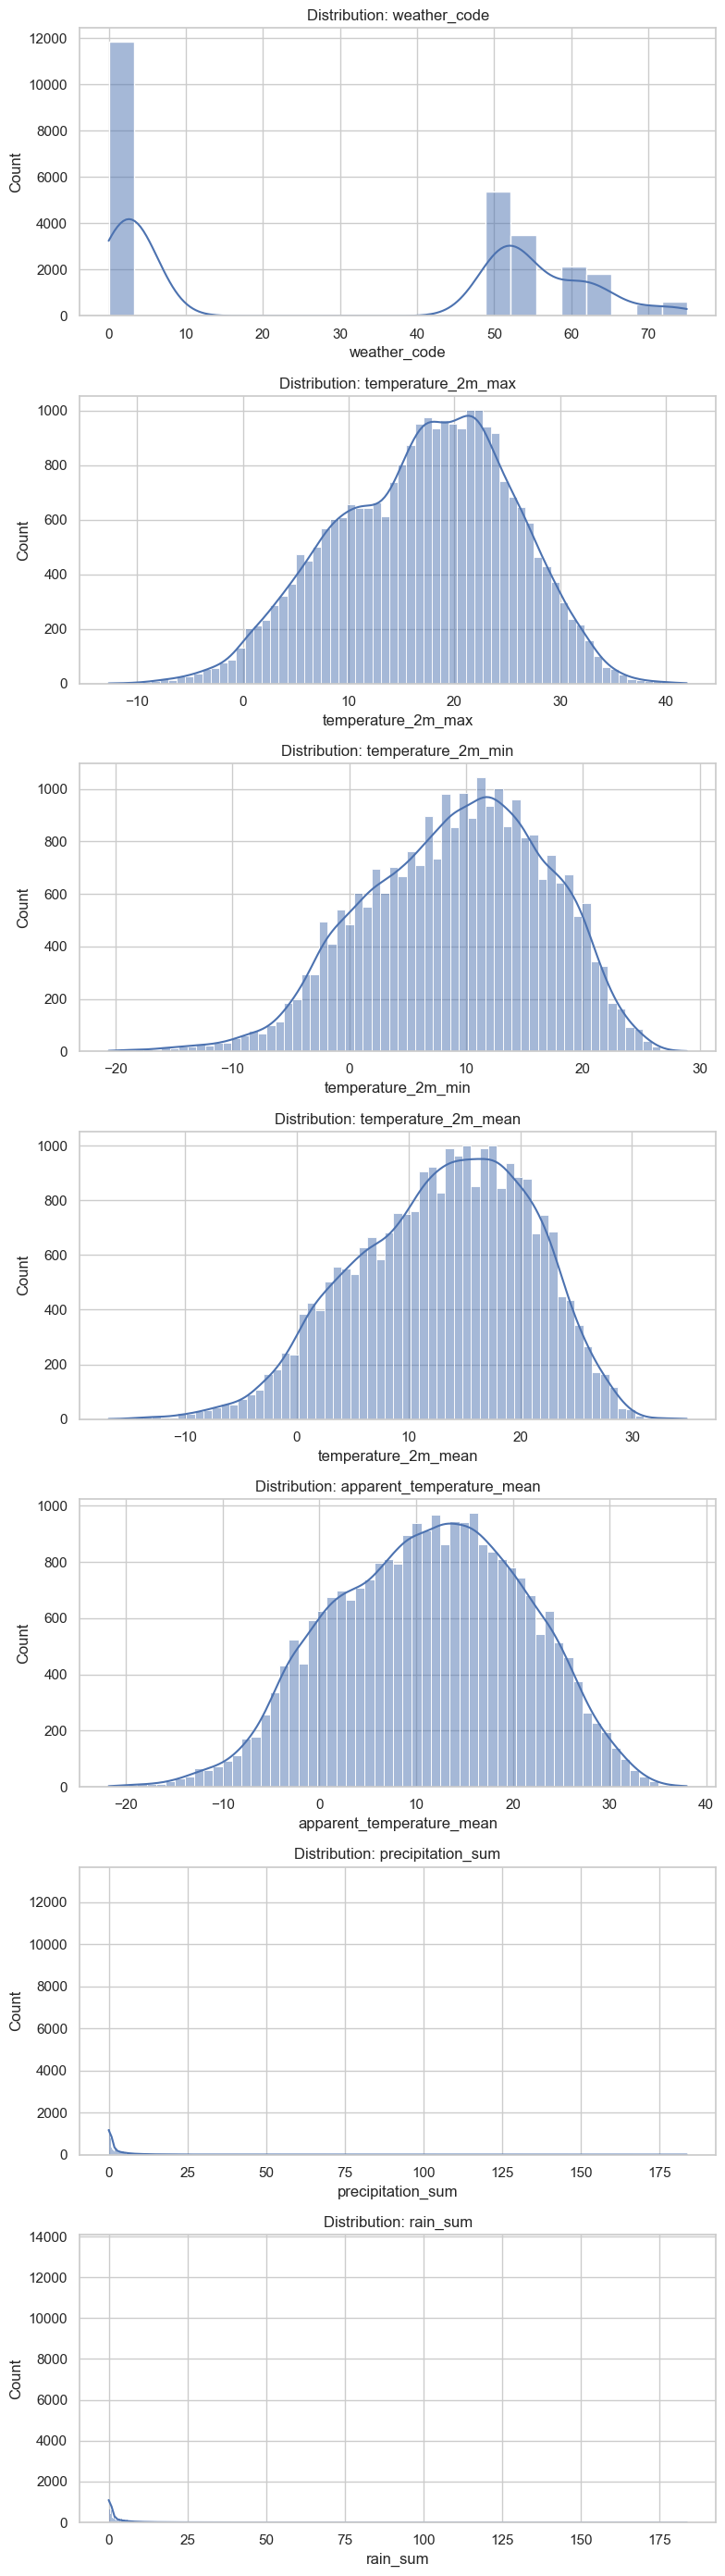

In [4]:
numeric_cols = [c for c in df.select_dtypes(include=["number"]).columns]
selected_cols = numeric_cols[:7]
fig, axes = plt.subplots(len(selected_cols), 1, figsize=(8, 4 * len(selected_cols)))
if len(selected_cols) == 1:
    axes = [axes]
for ax, col in zip(axes, selected_cols):
    sns.histplot(df[col].dropna(), kde=True, ax=ax)
    ax.set_title(f"Distribution: {col}")
plt.tight_layout()
plt.show()

## Target Creation: RainTomorrow
לפי ההוראות: בתוך כל location, לאחר מיון לפי date, RainTomorrow = 1 אם precipitation_sum של היום הבא ≥ 1.0 מ"מ, אחרת 0.
היום האחרון בכל מיקום נמחק (אין לו "מחר"). מידע מהיום הבא לא משמש כמאפיין.

In [5]:
df["date"] = pd.to_datetime(df["date"])
df = df.sort_values(["location", "date"]).reset_index(drop=True)

next_precip = df.groupby("location")["precipitation_sum"].shift(-1)
next_date = df.groupby("location")["date"].shift(-1)

# The label is valid only if the next row is really the next calendar day.
# This drops the last day of each location AND the day before any gap in the data
# (e.g. a missing year), so no row gets a label from a different date.
has_tomorrow = (next_date - df["date"]).dt.days.eq(1)
print("rows without a real 'tomorrow' (last day or gap):", int((~has_tomorrow).sum()))

df["RainTomorrow"] = (next_precip >= 1.0).astype(int)
df = df[has_tomorrow].reset_index(drop=True)
df[["location", "date", "precipitation_sum", "RainTomorrow"]].head(10)

rows without a real 'tomorrow' (last day or gap): 6


,location,date,precipitation_sum,RainTomorrow
0,berlin,2010-01-01,3.2,1
1,berlin,2010-01-02,1.1,0
2,berlin,2010-01-03,0.0,0
3,berlin,2010-01-04,0.0,0
4,berlin,2010-01-05,0.0,0
5,berlin,2010-01-06,0.0,0
6,berlin,2010-01-07,0.0,0
7,berlin,2010-01-08,0.3,1
8,berlin,2010-01-09,11.3,1
9,berlin,2010-01-10,7.3,1


In [6]:
# Fill missing values per city (a median over all cities mixes different climates)
num_cols = df.select_dtypes(include=["number"]).columns.drop("RainTomorrow")
print("missing before:", int(df[num_cols].isna().sum().sum()))
df[num_cols] = df.groupby("location")[num_cols].transform(lambda s: s.fillna(s.median()))
print("missing after:", int(df.isna().sum().sum()))

missing before: 0
missing after: 0


In [7]:
PROCESSED_PATH.parent.mkdir(parents=True, exist_ok=True)
df.to_csv(PROCESSED_PATH, index=False)
print(f"Saved: {PROCESSED_PATH}")

Saved: data\processed\final_dataset.csv
